# Detección de anomalías en la producción agrícola del Perú
## Encuesta Nacional Agropecuaria (ENA – INEI), 2014-2025

**Universidad Nacional del Altiplano – Puno** · Facultad de Ingeniería Estadística e Informática · Ciencia de Datos I (VIII semestre) · Docente: Fred Torres Cruz

**Integrantes:** Rommel Absalón Pacori Vera · Milton Flores Flores · Víctor Serapio Aquine Jimenez

**Problema.** Cada año la ENA registra, para cada productor, los cultivos que cosechó: superficie, producción y lo que vendió. Un registro con un rendimiento o un precio muy distinto al de su mismo cultivo, año y región puede ser un error de digitación, una confusión de unidades o un caso real fuera de lo común. Queremos **detectar automáticamente esos registros** con métodos no supervisados y **validar** la detección con todo el rango 2015-2025.

El trabajo se organiza en 5 etapas; cada una es una función del módulo `ena_anomalias.py`:

| Etapa | Funciones |
|---|---|
| 1. Carga e integración | `leer_sav`, `agregar_factor_parcela`, `leer_2025`, `integrar` |
| 2. Limpieza | `limpiar` |
| 3. Variables | `crear_variables`, `z_robusto` |
| 4. Modelos | `detectar_z`, `detectar_dbscan`, `elegir_k`, `detectar_kmeans`, `detectar_iforest`, `detectar_todo` |
| 5. Validación | `validar_silueta`, `validar_reglas`, `validar_inyeccion`, `validar_temporal` |


In [1]:
# Configuración: rutas de los datos (cambiar si se ejecuta en otra computadora)
RUTA_SAV  = '../data/raw/ENA_2014_2024.sav'   # microdatos INEI 2014-2024 (descomprimido)
RUTA_2025 = '../data/raw/2025'                # los 21 zip de 2025 tal cual
CARPETA   = '..'                               # raíz del repositorio (figuras/ y resultados/)

import sys, os, time, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, os.getcwd())  # el módulo está en scripts/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ena_anomalias as ea
os.makedirs(f'{CARPETA}/figuras', exist_ok=True); os.makedirs(f'{CARPETA}/resultados', exist_ok=True)
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

## Etapa 1 · Carga e integración

* **2014-2024:** un solo archivo SPSS de 14,7 GB (3 843 598 filas × 1 704 variables; todos los capítulos apilados). Solo leemos las columnas del capítulo 200 (cultivos cosechados) y de la parcela.
* **2025:** 21 zip con un CSV por capítulo; el capítulo 200 está en `03_CAP200AB.csv` (módulo 1895).
* Las variables tienen el mismo nombre en ambas fuentes, así que se unen con `integrar`.
* **Superficie en hectáreas.** El productor declara la superficie del cultivo en la unidad local de su parcela (m², topo, yugada…). El INEI publica la conversión (`P217_SUP_ha`) en todos los años **menos 2015 y 2018**; para esos dos años la reconstruimos con el factor de la parcela (`agregar_factor_parcela`).

In [2]:
t = time.time()
d_14_24 = ea.leer_sav(RUTA_SAV)
d_25 = ea.leer_2025(RUTA_2025)
datos = ea.integrar(d_14_24, d_25)
print(f'Filas leídas: {len(datos):,}  ({time.time()-t:.0f} s)')
datos.groupby('ANIO').size().rename('filas (todas las secciones)').to_frame().T

Filas leídas: 4,002,345  (203 s)


ANIO,2014,2015,2016,2017,2018,2019,2021,2022,2023,2024,2025
filas (todas las secciones),196962,251795,281677,284751,368718,366615,374116,291667,582748,844549,158747


**Comprobación de la reconstrucción de la superficie:** en los años donde el INEI sí publica las hectáreas, nuestro cálculo con el factor de la parcela debe dar lo mismo.

In [3]:
chk = datos[datos.P203.notna() & datos.P217_SUP_ha.notna() & datos.fac_parcela.notna()].copy()
recon = ea._entero_decimal(chk.P217_SUP_1, chk.P217_SUP_2) * pd.to_numeric(chk.fac_parcela)
oficial = pd.to_numeric(chk.P217_SUP_ha)
coincide = np.isclose(recon, oficial, rtol=0.01)
print(f'Registros comparados: {len(chk):,} · coinciden con el INEI: {coincide.mean():.2%}')
pd.Series(coincide).groupby(chk.ANIO.values).mean().rename('coincidencia').to_frame().T

Registros comparados: 783,865 · coinciden con el INEI: 100.00%


,2016,2017,2019,2021,2022,2023,2024
coincidencia,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Etapa 2 · Limpieza

Cada paso deja constancia de cuántos registros quedan (embudo de limpieza). Decisiones:
1. Solo las filas de la sección 200A (cultivo cosechado con número de cultivo).
2. Solo encuestas completas (`RESFIN = 1`).
3. **2014 se excluye del modelo**: el INEI no publicó superficie, cantidad ni valor de venta ese año (las columnas vienen vacías).
4. Los números vienen partidos en entero + decimales en texto (`'069'` = 0,069): se reconstruyen.
5. Se eliminan códigos de relleno (99 999 999), ceros y duplicados.
6. Se conservan los cultivos con 30 registros o más en el año (para comparar contra su grupo).

In [4]:
limpio, embudo = ea.limpiar(datos)
embudo.to_csv(f'{CARPETA}/resultados/embudo_limpieza.csv', index=False)
embudo

,Paso,Registros,Nota
0,Filas con nombre de cultivo (todas las secciones),1658156,
1,Registros de cultivos cosechados (sección 200A...,1493391,
2,Solo encuestas completas (RESFIN = 1),1492147,
3,Sin 2014 (INEI no publicó cantidades ni superf...,1413650,
4,"Con superficie, cantidad y equivalencia en kg",1267692,
5,Sin códigos de relleno (99 999 999 y similares),1267547,145 eliminados
6,Superficie y producción mayores que cero,1267547,
7,"Sin registros duplicados (mismo productor, par...",1267083,
8,Cultivos con 30 registros o más en el año,1250818,


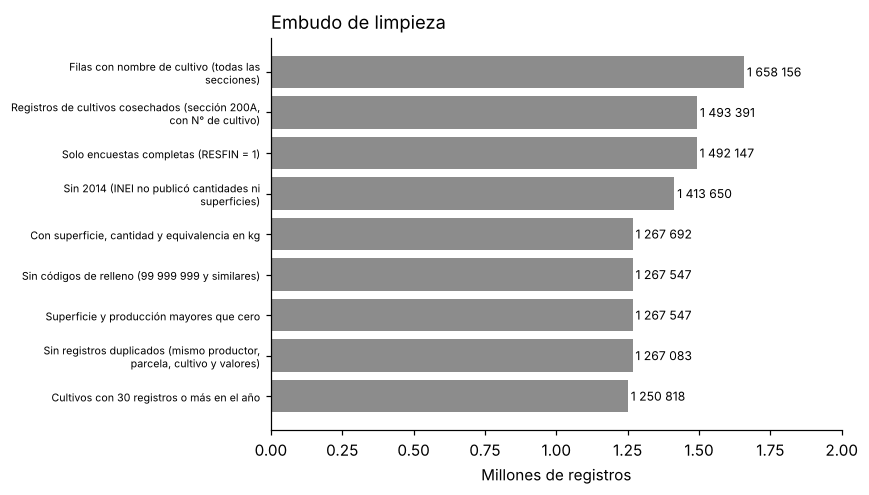

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
e = embudo.iloc[::-1]
ax.barh(range(len(e)), e.Registros/1e6, color='0.55')
import textwrap
ax.set_yticks(range(len(e)), [textwrap.fill(p, 48) for p in e.Paso], fontsize=7)
for i, v in enumerate(e.Registros): ax.text(v/1e6 + 0.01, i, f'{v:,}'.replace(',', ' '), va='center', fontsize=8)
ax.set_xlabel('Millones de registros'); ax.set_xlim(0, 2); ax.set_title('Embudo de limpieza', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f1_embudo.png', dpi=200); plt.show()

## Etapa 3 · Selección y construcción de variables (16 variables)

No usamos las cifras en bruto: un saco de papa y una tonelada de café no se comparan. Construimos **12 variables numéricas** con sentido agronómico, cada una comparada **contra su propio contexto** (mismo cultivo, año y región natural), y **4 categóricas**:

| # | Variable | Cómo se calcula | Tipo |
|---|---|---|---|
| 1 | Rendimiento | producción (kg) / superficie cosechada (ha) | z robusto del log |
| 2 | Precio de venta por kg | valor de venta / kg vendidos | z robusto del log |
| 3 | Superficie cosechada | ha | z robusto del log |
| 4 | Superficie sembrada | ha | z robusto del log |
| 5 | % de lo sembrado que se cosechó | ha cosechadas / ha sembradas | desvío respecto a su grupo |
| 6 | % de la producción vendida | cantidad vendida / producida | desvío |
| 7 | % para consumo del hogar | cantidad consumida / producida | desvío |
| 8 | % para alimento de animales | cantidad a animales / producida | desvío |
| 9 | % guardado como semilla | cantidad a semilla / producida | desvío |
| 10 | Número de cosechas en el año | P205 | desvío del log |
| 11 | Precio por kg del autoconsumo | valor del consumo / kg consumidos | z robusto del log |
| 12 | Meses entre siembra y cosecha | fecha de inicio de cosecha − fecha de siembra | desvío (2021 sin fecha de siembra → 0) |
| 13 | Tipo de cultivo | transitorio / permanente / otro | categórica (0/1) |
| 14 | Conducción | solo o asociado | categórica (0/1) |
| 15 | Fuente de agua | riego (río, pozo, …) o secano (lluvia) | categórica (0/1) |
| 16 | Región natural | Costa / Sierra / Selva | categórica (0/1) |

* **z robusto** = `(x − mediana) / (1,4826 × MAD)` dentro de cultivo × año × región. Mediana y MAD no se dejan arrastrar por las anomalías.
* **Desvío**: en proporciones y conteos la MAD suele ser 0 (casi todos venden el 100 % o nada), así que se usa la distancia a la mediana del grupo dividida entre la desviación estándar global.
* Un dato faltante (por ejemplo, el precio de quien no vende) queda en 0 = neutral.

Se mantiene también el **modelo base de 3 variables** (1-3) para comparar en la validación si las variables extra ayudan.

In [6]:
dv = ea.crear_variables(limpio)
del d_14_24, d_25, datos; import gc; gc.collect()
print('Variables del modelo ampliado:', len(ea.NUMERICAS), 'numéricas +', len(ea.CATEGORICAS), 'categóricas =',
      len(ea.NUMERICAS) + len(ea.CATEGORICAS), f'({len(ea.VARS_16)} columnas tras pasar las categóricas a 0/1)')
dv[ea.NUMERICAS].describe(percentiles=[.01, .5, .99]).T.round(2)

Variables del modelo ampliado: 12 numéricas + 4 categóricas = 16 (29 columnas tras pasar las categóricas a 0/1)


,count,mean,std,min,1%,50%,99%,max
z_rend,1250818.0,-0.08,1.15,-20.38,-3.37,0.0,2.47,15.27
z_precio,1250818.0,-0.00,0.81,-26.02,-2.42,0.0,2.38,30.46
z_area,1250818.0,-0.01,1.15,-32.00,-2.92,0.0,2.80,63.52
z_sembrada,1250818.0,-0.02,0.85,-47.96,-2.47,0.0,2.24,63.52
z_cosechado,1250818.0,-0.08,0.94,-17.64,0.00,0.0,0.00,70.57
z_venta,1250818.0,0.21,1.01,-2.67,-2.54,0.0,2.67,2.67
z_hogar,1250818.0,0.18,0.91,-3.10,-1.78,0.0,2.92,14.73
z_animales,1250818.0,-0.03,1.00,-5.38,-5.38,0.0,3.24,5.38
z_semilla,1250818.0,0.08,0.71,-3.01,-1.32,0.0,2.99,10.54
z_cosechas,1250818.0,0.21,1.32,-18.15,-3.06,0.0,4.32,20.48


In [7]:
pd.concat({ea.NOMBRES[c]: dv[c].astype(str).value_counts(normalize=True).round(3) for c in ea.CATEGORICAS},
          names=['Variable', 'Valor']).rename('Proporción').to_frame()

Proporción
Variable                        Valor             
Tipo de cultivo                 1.0          0.507
                                3.0          0.247
                                2.0          0.245
Conducción (solo o asociado)    1.0          0.688
                                3.0          0.169
                                2.0          0.108
                                4.0          0.035
Fuente de agua (riego o secano) 1.0          0.514
                                2.0          0.254
                                3.0          0.114
                                6.0          0.050
                                5.0          0.033
                                4.0          0.021
                                7.0          0.014
Región natural                  Sierra       0.617
                                Selva        0.196
                                Costa        0.187

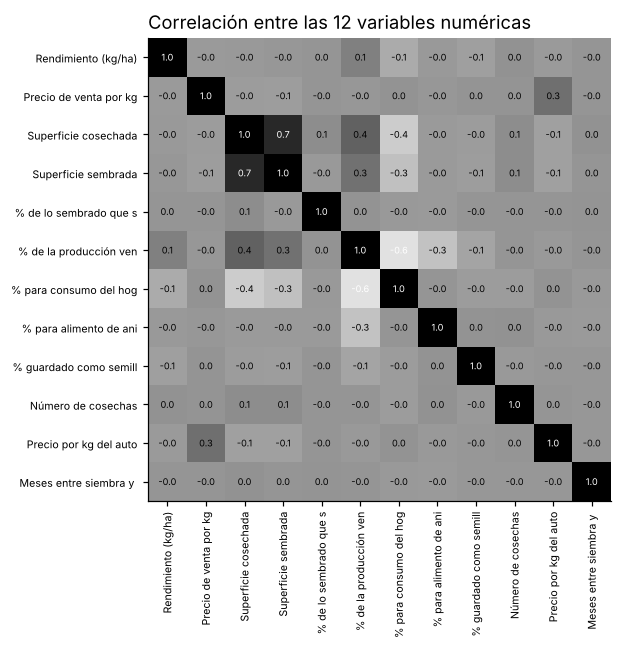

Correlación absoluta máxima fuera de la diagonal: 0.73


In [8]:
corr = dv[ea.NUMERICAS].corr().round(2); corr.index = corr.columns = [ea.NOMBRES[v][:22] for v in ea.NUMERICAS]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap='Greys', vmin=-1, vmax=1)
ax.set_xticks(range(12), corr.columns, rotation=90, fontsize=7); ax.set_yticks(range(12), corr.index, fontsize=7)
for i in range(12):
    for j in range(12): ax.text(j, i, f'{corr.iloc[i, j]:.1f}', ha='center', va='center', fontsize=6, color='white' if abs(corr.iloc[i, j]) > .5 else 'black')
ax.set_title('Correlación entre las 12 variables numéricas', loc='left'); plt.tight_layout()
plt.savefig(f'{CARPETA}/figuras/f0_correlacion.png', dpi=200); plt.show()
print('Correlación absoluta máxima fuera de la diagonal:', (corr.abs().where(~np.eye(12, dtype=bool))).max().max())

## Etapa 4 · Modelos

Usamos los mismos cuatro métodos del artículo de referencia (Herreros-Martínez et al., 2024) y los combinamos por votación:

* **Z-score robusto:** anómalo si |z| de rendimiento o de precio > 3,5 (criterio de Iglewicz y Hoaglin).
* **DBSCAN:** anómalo si queda como *ruido* (sin vecindario denso). Para que corra con 1,25 millones de filas se agrupan puntos casi iguales y se usan pesos.
* **k-Means:** anómalo si está en el 1 % más lejano del centro de su grupo; *k* se elige con la silueta.
* **Isolation Forest:** anómalo si se aísla con pocos cortes (1 % de contaminación).
* **Votación:** un registro es **anomalía final** si lo marcan **2 o más** métodos.

El z-score se aplica a las 5 variables continuas (rendimiento, precios y superficies); las proporciones y conteos entran en los otros tres métodos. DBSCAN no escala a 1,25 millones de filas en 16 dimensiones, así que se ajusta con una muestra de 40 000 (eps = percentil 98 de la curva k-distancia) y cada registro se clasifica según su distancia al punto núcleo más cercano.

In [9]:
sil_k = ea.elegir_k(dv, ea.VARS_16)
print({k: round(v, 3) for k, v in sil_k.items()})
K = max(sil_k, key=sil_k.get); print('k elegido =', K)

{2: 0.096, 3: 0.11, 4: 0.091, 5: 0.101, 6: 0.089, 7: 0.102, 8: 0.106}
k elegido = 3


In [10]:
t = time.time()
d3 = ea.detectar_todo(dv, ea.VARS_3, k=3, copiar=False)[['flag_z', 'flag_if', 'flag_km', 'flag_db', 'anomalia']].copy()
d = ea.detectar_todo(dv, ea.VARS_16, k=K, copiar=False)   # mismo DataFrame, ahora con las banderas del modelo de 16
del dv; gc.collect()
print(f'({time.time()-t:.0f} s)')
comp = pd.DataFrame({'3 variables (%)': 100*d3.mean(), '16 variables (%)': 100*d[list(ea.FLAGS.values())].mean()})
comp.index = list(ea.FLAGS.keys()); comp.to_csv(f'{CARPETA}/resultados/marcados_3_vs_16.csv'); display(comp.round(2))
print('Coinciden como anomalía final en ambos modelos:', int(((d.anomalia == 1) & (d3.anomalia.values == 1)).sum()))
print('Modelo de 16 variables:')
resumen = pd.DataFrame({'Marcados': d[list(ea.FLAGS.values())].sum(), '%': 100*d[list(ea.FLAGS.values())].mean()})
resumen.index = list(ea.FLAGS.keys()); resumen.round(2)

(126 s)


,3 variables (%),16 variables (%)
Z-score robusto,2.53,2.90
Isolation Forest,1.00,1.00
k-Means,1.00,1.00
DBSCAN,0.98,0.61
Votación (≥2),1.29,0.70


Coinciden como anomalía final en ambos modelos: 4003
Modelo de 16 variables:


,Marcados,%
Z-score robusto,36261,2.90
Isolation Forest,12509,1.00
k-Means,12509,1.00
DBSCAN,7678,0.61
Votación (≥2),8802,0.70


In [11]:
print('Número de métodos que marcan cada registro:'); d.votos.value_counts().sort_index().to_frame().T

Número de métodos que marcan cada registro:


votos,0,1,2,3,4
count,1194672,47344,5437,2721,644


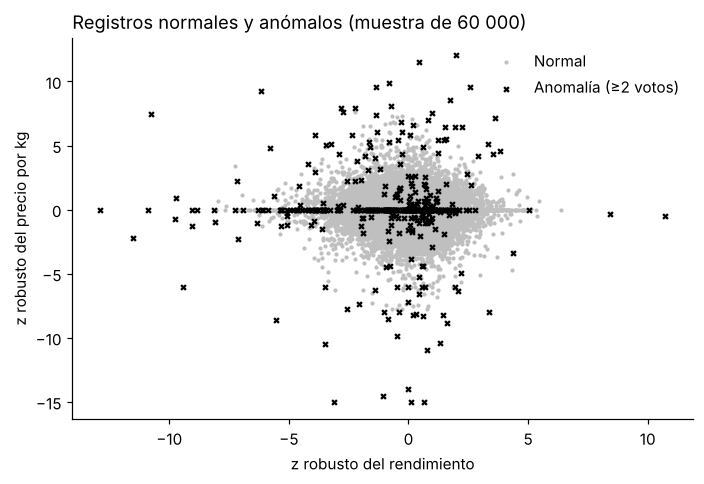

In [12]:
s = d.sample(60000, random_state=1)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
n = s[s.anomalia == 0]; a = s[s.anomalia == 1]
ax.scatter(n.z_rend.clip(-25, 25), n.z_precio.clip(-15, 15), s=3, c='0.75', label='Normal', rasterized=True)
ax.scatter(a.z_rend.clip(-25, 25), a.z_precio.clip(-15, 15), s=10, c='black', marker='x', label='Anomalía (≥2 votos)')
ax.set_xlabel('z robusto del rendimiento'); ax.set_ylabel('z robusto del precio por kg')
ax.set_title('Registros normales y anómalos (muestra de 60 000)', loc='left'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f2_dispersion.png', dpi=200); plt.show()

## Resultados descriptivos

In [13]:
por_anio = d.groupby('ANIO').agg(registros=('anomalia', 'size'), anomalias=('anomalia', 'sum'))
por_anio['%'] = 100*por_anio.anomalias/por_anio.registros
por_anio.to_csv(f'{CARPETA}/resultados/anomalias_por_anio.csv'); por_anio.round(2).T

ANIO,2015,2016,2017,2018,2019,2021,2022,2023,2024,2025
registros,102727.00,122010.00,125372.00,122888.00,121039.00,120740.00,103881.00,111099.00,163968.00,157094.00
anomalias,1069.00,1068.00,993.00,1236.00,828.00,739.00,783.00,544.00,838.00,704.00
%,1.04,0.88,0.79,1.01,0.68,0.61,0.75,0.49,0.51,0.45


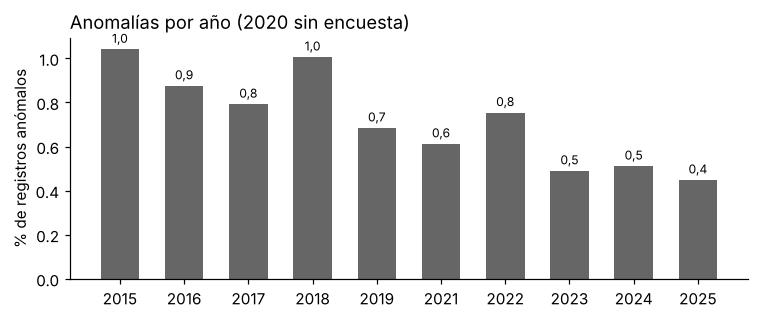

In [14]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(por_anio.index.astype(str), por_anio['%'], color='0.4', width=0.6)
for i, v in enumerate(por_anio['%']): ax.text(i, v + 0.03, f'{v:.1f}'.replace('.', ','), ha='center', fontsize=8)
ax.set_ylabel('% de registros anómalos'); ax.set_title('Anomalías por año (2020 sin encuesta)', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f3_por_anio.png', dpi=200); plt.show()

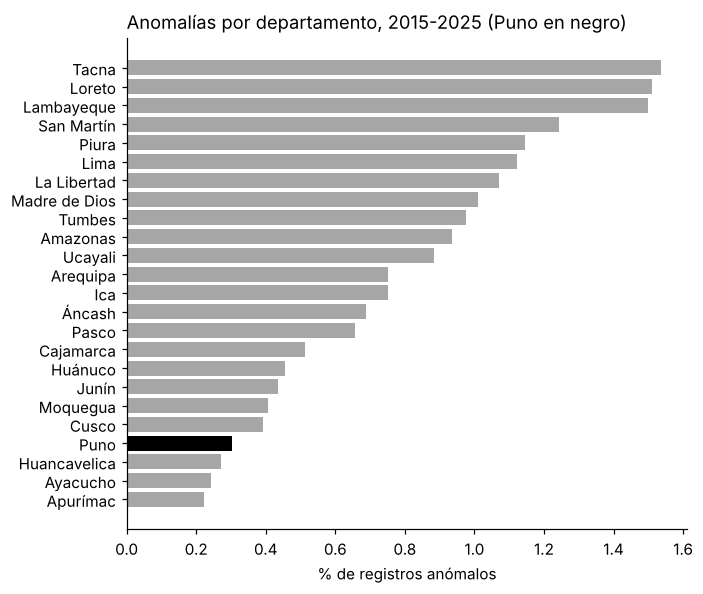

In [15]:
por_dep = d.groupby('departamento').agg(registros=('anomalia', 'size'), anomalias=('anomalia', 'sum'))
por_dep = por_dep[por_dep.registros > 1000]
por_dep['%'] = 100*por_dep.anomalias/por_dep.registros
por_dep = por_dep.sort_values('%'); por_dep.to_csv(f'{CARPETA}/resultados/anomalias_por_departamento.csv')
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.barh(por_dep.index, por_dep['%'], color=['black' if x == 'Puno' else '0.65' for x in por_dep.index])
ax.set_xlabel('% de registros anómalos'); ax.set_title('Anomalías por departamento, 2015-2025 (Puno en negro)', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f4_departamentos.png', dpi=200); plt.show()

In [16]:
por_cultivo = d.groupby('cultivo').agg(registros=('anomalia', 'size'), anomalias=('anomalia', 'sum'))
por_cultivo['%'] = 100*por_cultivo.anomalias/por_cultivo.registros
por_cultivo = por_cultivo[por_cultivo.registros >= 5000].sort_values('%', ascending=False)
por_cultivo.to_csv(f'{CARPETA}/resultados/anomalias_por_cultivo.csv'); por_cultivo.head(10).round(2)

,registros,anomalias,%
cultivo,,,
MAIZ CHALA,12278,531,4.32
ARROZ CASCARA,30695,876,2.85
YUCA,21762,607,2.79
OREGANO,5608,138,2.46
COCA,5348,103,1.93
CACAO,21457,258,1.20
MAIZ AMARILLO DURO,37156,406,1.09
CAFE PERGAMINO,34661,272,0.78
PLATANO,66373,367,0.55


**¿Qué variables explican las anomalías?** Comparamos qué tan lejos de lo típico están los anómalos frente a los normales en cada variable.

In [17]:
imp = ea.importancia_variables(d, ea.VARS_16)
imp.to_csv(f'{CARPETA}/resultados/importancia_variables.csv', index=False); imp.round(2)

,Variable,|z| medio anómalos,|z| medio normales,"% anómalos con |z|>3,5",Razón
4,% de lo sembrado que se cosechó,2.65,0.06,22.06,43.43
9,Número de cosechas,3.17,0.29,37.41,11.12
1,Precio de venta por kg,1.70,0.37,19.22,4.66
3,Superficie sembrada,1.93,0.43,20.17,4.51
2,Superficie cosechada,2.65,0.83,30.40,3.17
10,Precio por kg del autoconsumo,1.33,0.47,12.99,2.83
7,% para alimento de animales,0.74,0.27,11.46,2.78
0,Rendimiento (kg/ha),1.94,0.85,19.04,2.28
5,% de la producción vendida,1.23,0.58,0.00,2.13
6,% para consumo del hogar,0.97,0.58,0.02,1.68


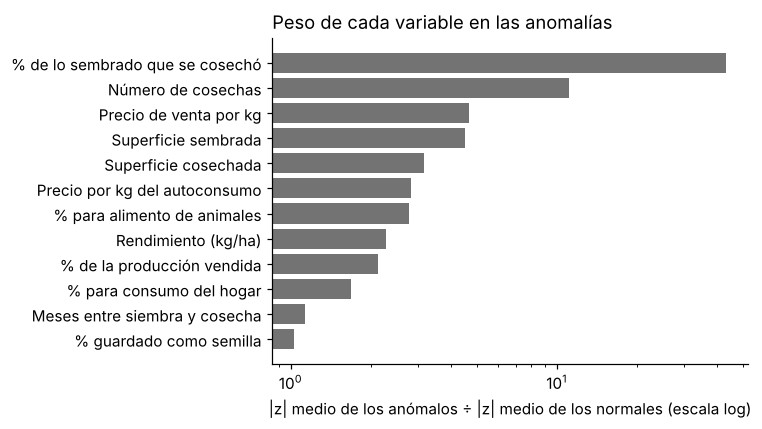

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
im2 = imp.sort_values('Razón')
ax.barh(im2.Variable, im2['Razón'], color='0.45'); ax.set_xscale('log')
ax.set_xlabel('|z| medio de los anómalos ÷ |z| medio de los normales (escala log)')
ax.set_title('Peso de cada variable en las anomalías', loc='left'); plt.tight_layout()
plt.savefig(f'{CARPETA}/figuras/f7_importancia.png', dpi=200); plt.show()

In [19]:
cols = ['ANIO', 'departamento', 'cultivo', 'area_ha', 'sembrada_ha', 'prod_kg', 'rend_kg_ha', 'precio_kg', 'n_cosechas', 'z_rend', 'z_precio', 'z_cosechado', 'z_cosechas', 'votos']
top = d[d.anomalia == 1].sort_values(['votos', 'score_if'], ascending=False)
top[cols].head(15).to_csv(f'{CARPETA}/resultados/top_anomalias_nacional.csv', index=False)
top[cols].head(10).round(2)

,ANIO,departamento,cultivo,area_ha,sembrada_ha,prod_kg,rend_kg_ha,precio_kg,n_cosechas,z_rend,z_precio,z_cosechado,z_cosechas,votos
1238142,2025,Tacna,LECHUGA,0.00,0.01,70.0,23333.33,NaN,1.0,0.89,0.0,-10.08,-4.32,4
810762,2022,Tacna,ESPINACA,0.00,0.00,1.2,12000.00,NaN,2.0,0.48,0.0,0.00,0.00,4
1018469,2024,Huánuco,CAÑA DE AZUCAR PARA AZUCAR,0.00,0.01,120.0,24000.00,0.67,1.0,-6.88,5.0,-8.82,0.00,4
1123730,2025,Arequipa,LECHUGA,0.01,0.02,60.0,6000.00,NaN,1.0,-1.84,0.0,-5.88,-4.32,4
811329,2022,Tacna,PEREJIL,0.00,0.00,2.0,20000.00,NaN,1.0,2.82,0.0,0.00,-9.75,4
810769,2022,Tacna,PEREJIL,0.00,0.00,1.5,15000.00,NaN,2.0,1.95,0.0,0.00,-5.44,4
811045,2022,Tacna,AJO,0.00,0.00,1.5,15000.00,NaN,6.0,0.83,0.0,0.00,13.34,4
811046,2022,Tacna,AJO,0.00,0.00,1.5,15000.00,NaN,6.0,0.83,0.0,0.00,13.34,4
811047,2022,Tacna,AJO,0.00,0.00,1.5,15000.00,NaN,6.0,0.83,0.0,0.00,13.34,4
811048,2022,Tacna,AJO,0.00,0.00,1.5,15000.00,NaN,6.0,0.83,0.0,0.00,13.34,4


In [20]:
puno = d[d.departamento == 'Puno']
print(f'Puno: {len(puno):,} registros · {puno.anomalia.sum():,} anómalos ({puno.anomalia.mean():.2%})')
pt = puno[puno.anomalia == 1].sort_values(['votos', 'score_if'], ascending=False)
pt[cols].head(15).to_csv(f'{CARPETA}/resultados/top_anomalias_puno.csv', index=False)
display(puno[puno.anomalia == 1].cultivo.value_counts().head(8).rename('anomalías').to_frame().T)
pt[cols].head(8).round(2)

Puno: 79,148 registros · 240 anómalos (0.30%)


cultivo,PAPA NATIVA,COCA,AVENA FORRAJERA,QUINUA,ROCOTO,PLATANO,AVENA GRANO,HABA GRANO SECO
anomalías,41,23,23,19,18,17,15,9


,ANIO,departamento,cultivo,area_ha,sembrada_ha,prod_kg,rend_kg_ha,precio_kg,n_cosechas,z_rend,z_precio,z_cosechado,z_cosechas,votos
804380,2022,Puno,ROCOTO,0.01,0.01,30.0,3000.00,NaN,1.0,-0.81,0.00,0.00,-7.38,4
804465,2022,Puno,ROCOTO,0.00,0.00,7.0,7000.00,NaN,1.0,0.47,0.00,0.00,-7.38,4
800264,2022,Puno,PASTO DACTYLIS,0.16,0.00,8000.0,50000.00,0.5,1.0,2.41,13.98,0.00,0.00,4
800300,2022,Puno,PASTO BRIZANTA,0.20,0.00,1000.0,5000.00,0.5,1.0,-2.69,13.78,0.00,0.00,4
89276,2015,Puno,ESPINACA,0.00,0.00,1.0,5000.00,NaN,1.0,-1.25,0.00,0.00,-4.32,3
88999,2015,Puno,ROCOTO,0.02,0.02,135.0,6750.00,NaN,3.0,-0.40,0.00,0.00,7.38,3
1071206,2024,Puno,ROCOTO,0.10,0.50,250.0,2500.00,2.1,2.0,-1.54,0.08,-14.10,4.44,3
87404,2015,Puno,AJO,0.00,0.00,1.0,3333.33,NaN,1.0,-0.93,0.00,-8.82,0.00,3


In [21]:
d[['ANIO', 'departamento', 'region', 'cultivo', 'area_ha', 'sembrada_ha', 'prod_kg', 'rend_kg_ha', 'precio_kg', 'n_cosechas'] + ea.NUMERICAS + [
   'flag_z', 'flag_if', 'flag_km', 'flag_db', 'votos', 'anomalia']].query('votos >= 1').to_csv(f'{CARPETA}/resultados/registros_marcados.csv', index=False)

## Etapa 5 · Validación

No existe una lista oficial de registros erróneos (no hay etiquetas), igual que en el artículo. Por eso validamos de **cuatro formas**, de la más débil a la más fuerte:

1. **Silueta** (lo que hizo el artículo): ¿los grupos están bien separados?
2. **Anomalías conocidas por reglas lógicas** que el modelo **no ve** (por ejemplo, valor de venta ≠ cantidad × precio unitario): ¿los métodos las detectan más que al azar?
3. **Errores inyectados:** metemos a propósito errores típicos de digitación en registros normales y medimos precisión, recall, F1 y AUC (aquí **sí** conocemos la respuesta).
4. **Validación temporal con todo el rango:** el modelo aprende con los años anteriores y se prueba en el año siguiente (2016, 2017, …, 2025).

### 5.1 Silueta

In [22]:
sil = pd.Series(ea.validar_silueta(d, ea.VARS_16, k=K)).rename('Silueta').round(3)
sil.to_csv(f'{CARPETA}/resultados/silueta.csv'); sil.to_frame()

,Silueta
k-Means (k=3),0.110
Normal vs anómalo: Z-score robusto,0.352
Normal vs anómalo: Isolation Forest,0.307
Normal vs anómalo: k-Means,0.638
Normal vs anómalo: DBSCAN,0.614
Normal vs anómalo: Votación (≥2),0.591


### 5.2 Anomalías conocidas por reglas

In [23]:
vr, reglas = ea.validar_reglas(d)
print(reglas.sum().rename('casos').to_string())
vr3, _ = ea.validar_reglas(d.assign(**{c: d3[c].values for c in d3.columns}))
vr['Modelo'] = '16 variables'; vr3['Modelo'] = '3 variables'
vr = pd.concat([vr3, vr]); vr.to_csv(f'{CARPETA}/resultados/validacion_reglas.csv', index=False)
vr[vr.Casos > 10].round(2)

R1 vendió más de lo que cosechó                 0
R2 cosechó más superficie de la que sembró      3
R3 valor ≠ cantidad × precio                  206


,Regla,Casos,Método,Detectadas (%),Marcadas en el resto (%),Lift,Modelo
10,R3 valor ≠ cantidad × precio,206,Z-score robusto,14.08,2.53,5.57,3 variables
11,R3 valor ≠ cantidad × precio,206,Isolation Forest,12.14,1.00,12.16,3 variables
12,R3 valor ≠ cantidad × precio,206,k-Means,11.65,1.00,11.67,3 variables
13,R3 valor ≠ cantidad × precio,206,DBSCAN,12.14,0.98,12.41,3 variables
14,R3 valor ≠ cantidad × precio,206,Votación (≥2),13.11,1.29,10.14,3 variables
10,R3 valor ≠ cantidad × precio,206,Z-score robusto,17.96,2.90,6.20,16 variables
11,R3 valor ≠ cantidad × precio,206,Isolation Forest,3.40,1.00,3.40,16 variables
12,R3 valor ≠ cantidad × precio,206,k-Means,6.80,1.00,6.80,16 variables
13,R3 valor ≠ cantidad × precio,206,DBSCAN,9.71,0.61,15.86,16 variables
14,R3 valor ≠ cantidad × precio,206,Votación (≥2),10.68,0.70,15.21,16 variables


### 5.3 Errores inyectados (1 % de los registros)
* **A)** un cero de más en la cantidad producida (× 10)
* **B)** confusión kilogramo ↔ tonelada (× 1 000 o ÷ 1 000)
* **C)** un cero de más en el valor de venta (× 10)
* **D)** un cero de más en la superficie sembrada (× 10)
* **E)** un cero de más en el número de cosechas (× 10)

A, B y C afectan a las variables del modelo base (3 variables); D y E solo a variables que agrega el modelo de 16. Así la comparación es justa para ambos.

Los registros que ya eran anómalos en los datos reales no se cuentan como falsos positivos.

In [24]:
t = time.time()
d_vars = {'3 variables': (ea.VARS_3, 3), '16 variables': (ea.VARS_16, K)}
del d3, d; gc.collect()   # se libera memoria: la validación vuelve a construir todo desde los datos limpios
vis, tipos = {}, {}
for nom, (V, kk) in d_vars.items():
    vis[nom], tipos[nom] = ea.validar_inyeccion(limpio, V, k=kk); gc.collect()
print(f'({time.time()-t:.0f} s)')
vi = pd.concat(vis, names=['Modelo']); vi.to_csv(f'{CARPETA}/resultados/validacion_inyeccion.csv'); vi.round(3)

(256 s)


Precisión  Recall     F1    AUC
Modelo       Método                                           
3 variables  Z-score robusto       0.242   0.534  0.333  0.797
             Isolation Forest      0.534   0.177  0.266  0.791
             k-Means               1.000   0.438  0.609  0.799
             DBSCAN                0.998   0.408  0.579  0.775
             Votación (≥2)         0.992   0.448  0.617  0.764
16 variables Z-score robusto       0.152   0.543  0.238  0.829
             Isolation Forest      0.043   0.042  0.042  0.752
             k-Means               0.670   0.654  0.662  0.981
             DBSCAN                0.858   0.348  0.495  0.931
             Votación (≥2)         0.944   0.368  0.530  0.949

In [25]:
por_tipo = pd.concat(tipos, names=['Modelo'])
por_tipo.columns = list(ea.FLAGS.keys()); por_tipo.index = [f'{m}: ' + {'A': 'A) producción × 10', 'B': 'B) kg ↔ t', 'C': 'C) valor × 10', 'D': 'D) sembrada × 10', 'E': 'E) cosechas × 10'}[t] for m, t in por_tipo.index]
por_tipo.to_csv(f'{CARPETA}/resultados/recall_por_tipo_error.csv'); print('Recall (%) por tipo de error'); por_tipo.round(1)

Recall (%) por tipo de error


,Z-score robusto,Isolation Forest,k-Means,DBSCAN,Votación (≥2)
3 variables: A) producción × 10,74.5,7.4,41.4,32.6,43.9
3 variables: B) kg ↔ t,100.0,32.4,99.9,99.6,99.9
3 variables: C) valor × 10,86.7,70.7,74.6,68.2,77.8
3 variables: D) sembrada × 10,0.0,0.0,0.0,0.0,0.0
3 variables: E) cosechas × 10,0.0,0.0,0.0,0.0,0.0
16 variables: A) producción × 10,73.8,0.8,2.5,8.6,9.1
16 variables: B) kg ↔ t,100.0,8.1,94.7,97.3,97.5
16 variables: C) valor × 10,87.1,2.0,20.4,26.6,28.4
16 variables: D) sembrada × 10,7.2,3.5,100.0,14.3,20.7
16 variables: E) cosechas × 10,0.0,5.0,99.2,12.3,15.4


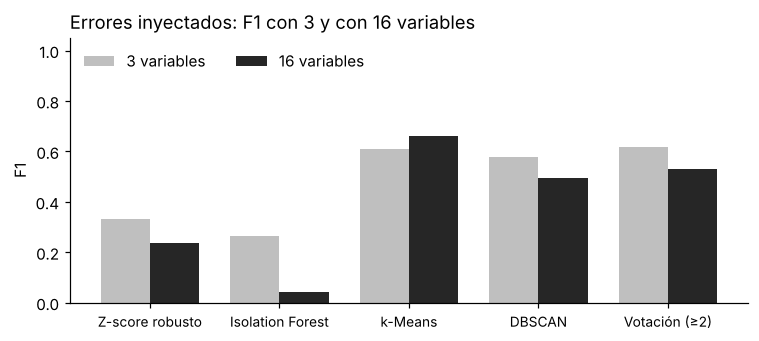

In [26]:
fig, ax = plt.subplots(figsize=(7, 3.2))
f1 = vi['F1'].unstack(0)[['3 variables', '16 variables']].loc[list(ea.FLAGS.keys())]
x = np.arange(len(f1)); w = 0.38
ax.bar(x - w/2, f1['3 variables'], w, color='0.75', label='3 variables')
ax.bar(x + w/2, f1['16 variables'], w, color='0.15', label='16 variables')
ax.set_xticks(x, f1.index, fontsize=9); ax.set_ylim(0, 1.05); ax.legend(frameon=False, ncol=2, loc='upper left')
ax.set_ylabel('F1'); ax.set_title('Errores inyectados: F1 con 3 y con 16 variables', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f5_inyeccion.png', dpi=200); plt.show()

### 5.4 Validación temporal (entrenar con años anteriores, probar en el siguiente)

In [27]:
t = time.time()
vts = {nom: ea.validar_temporal(limpio, V, k=kk) for nom, (V, kk) in d_vars.items()}
print(f'({time.time()-t:.0f} s)')
vt = pd.concat(vts, names=['Modelo']).reset_index(level=0)
vt.to_csv(f'{CARPETA}/resultados/validacion_temporal.csv', index=False); vt.round(3)

(557 s)


,Modelo,Año de prueba,Entrenado con,Registros,Marcados (%),Precisión IF,Recall IF,F1 IF,AUC IF,Precisión Votación,Recall Votación,F1 Votación,AUC Votación
0,3 variables,2016,2015,122010,1.854,0.326,0.073,0.120,0.773,0.982,0.465,0.631,0.761
1,3 variables,2017,2015-2016,125372,1.300,0.472,0.125,0.197,0.802,0.976,0.483,0.646,0.777
2,3 variables,2018,2015-2017,122888,1.911,0.428,0.135,0.205,0.793,0.996,0.485,0.652,0.776
3,3 variables,2019,2015-2018,121039,1.584,0.460,0.129,0.201,0.792,0.994,0.491,0.658,0.777
4,3 variables,2021,2015-2019,120740,1.322,0.486,0.104,0.171,0.775,0.998,0.459,0.629,0.764
5,3 variables,2022,2015-2021,103881,1.685,0.280,0.090,0.136,0.772,0.985,0.486,0.651,0.777
6,3 variables,2023,2015-2022,111099,1.034,0.431,0.100,0.162,0.790,0.975,0.447,0.613,0.758
7,3 variables,2024,2015-2023,163968,1.285,0.418,0.113,0.178,0.792,0.998,0.440,0.611,0.753
8,3 variables,2025,2015-2024,157094,1.072,0.377,0.100,0.158,0.804,0.996,0.459,0.628,0.757
0,16 variables,2016,2015,122010,1.034,0.030,0.028,0.029,0.729,0.956,0.498,0.655,0.951


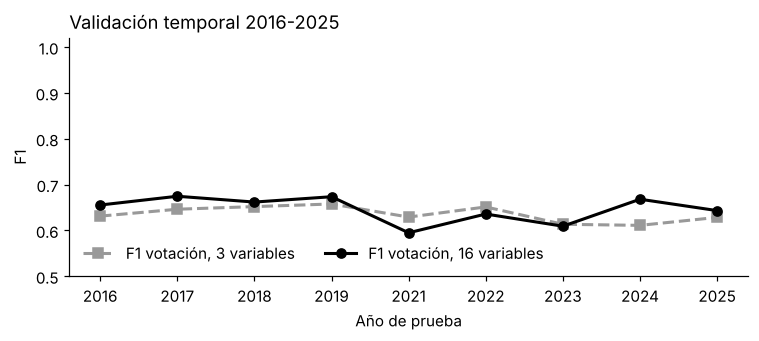

In [28]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for nom, est in [('3 variables', dict(color='0.6', ls='--', marker='s')), ('16 variables', dict(color='black', ls='-', marker='o'))]:
    v = vt[vt.Modelo == nom]
    ax.plot(v['Año de prueba'].astype(str), v['F1 Votación'], lw=2, label=f'F1 votación, {nom}', **est)
ax.set_ylim(0.5, 1.02); ax.set_xlabel('Año de prueba'); ax.set_ylabel('F1'); ax.legend(frameon=False, ncol=2, loc='lower left')
ax.set_title('Validación temporal 2016-2025', loc='left')
plt.tight_layout(); plt.savefig(f'{CARPETA}/figuras/f6_temporal.png', dpi=200); plt.show()

## Conclusiones

Ver el informe en PDF: allí se discuten los resultados del modelo de 16 variables, la comparación con el de 3 y las limitaciones.